# The Linear Time-Discrete Kalman Filter (LDKF)

Course: Recursive State Estimation for Dynamic Systems (SoSe 2026)

Institute: Geodätisches Institut Hannover

Team Members :

1.Arjun Mohandas( Matriculation Nummer:10081891)

2.Aswin Sam(Matriculation Nummer:10082498)

3.Edvin Tony Thampy(Matriculation Nummer:10082986)

This notebook implements the Classical Kalman Filter for estimating the 3D position and velocity of a robot from noisy total-station observations.

The implementation follows the notation used in the lecture and exercise sessions.

## Use Of AI

ChatGPT was used for coding review, debugging assistance and researching information.It was mainly used to summarise topics and informations and document them into latex code including equations which were too lengthy and time consuming too write.It was used to understand and minimize code implementations and document information, handle data, plot graphs and diagrams with ease. It was mainly used to check for errors in code and evaluate diagrams to understand their behaviour.The implementations differed from filter to filter.Eventhough AI was used all implementation decisions and final results were verified by us.



# AIM

To estimate the 3D position and velocity of a kinematic robot from noisy total-station observations.

$$
\mathbf{x}^{(k)}=
\begin{bmatrix}
X^{(k)}\\
Y^{(k)}\\
Z^{(k)}\\
v_X^{(k)}\\
v_Y^{(k)}\\
v_Z^{(k)}
\end{bmatrix}
$$

where $\left(X^{(k)},Y^{(k)},Z^{(k)}\right)$ represent the Cartesian position coordinates and $\left(v_X^{(k)},v_Y^{(k)},v_Z^{(k)}\right)$ represent the Cartesian velocity components of the current state.

From noisy total-station observations:

$$
\mathbf{l}^{(k)}=
\begin{bmatrix}
H^{(k)}\\
V^{(k)}\\
D^{(k)}
\end{bmatrix}
$$

The total station measures $(H,V,D)$, where $H$ is the horizontal angle, $V$ is the zenith angle, and $D$ is the slope distance. These quantities are known as the polar observations.


# PRE-PROCESSING

## Imports and Loading given datafiles

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Read observation and ground truth data
obsrv = pd.read_csv("Data/polar0011_slower_0.csv")
gtrue = pd.read_csv("Data/tracker0011_slower_0.csv")

## Polar to Cartesian Transformation

LKDF requires a linear system and a linear observation model. The given observations are in polar coordinates (H,V,D) which are non-linear, so they must be transformed to cartesian coordinates. The equations to convert polar coordinates to cartesian is given below:

$$
X=D\sin(V)\cos(H)
$$

$$
Y=D\sin(V)\sin(H)
$$

$$
Z=D\cos(V)
$$

where X, Y and Z are the cartesian position coordinates.

In [22]:
#Conversion of observations from polar coordinates to cartesian coordinates:
obsrv["H_radian"] = np.deg2rad(obsrv["H [deg]"]) #degree to radian conversion
obsrv["V_radian"]= np.deg2rad(obsrv["V [deg]"])
obsrv["D_m"]= obsrv["D [mm]"] / 1000  #mm to m conversion


X_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.cos(obsrv["H_radian"] )

Y_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.sin(obsrv["H_radian"] )

Z_obsrv = obsrv["D_m"]*np.cos(obsrv["V_radian"])

obsrv["X_obsrv_cart"] = X_obsrv
obsrv["Y_obsrv_cart"] = Y_obsrv
obsrv["Z_obsrv_cart"] = Z_obsrv

X_gtrue = gtrue["X [m]"].values #converting pandas to numpy
Y_gtrue = gtrue["Y [m]"].values
Z_gtrue = gtrue["Z [m]"].values


## Time Interval or Step length
$$
\Delta t^{(k)} = t^{(k+1)} - t^{(k)}
$$

represents the elapsed time between consecutive observations. It is a fundamental parameter in the Kalman Filter as it determines the propagation of the state vector through the dynamic model. The transition matrix contains $\Delta t^{(k)}$ terms that relate position and velocity according to

$$
X^{(k+1)} = X^{(k)} + v_X^{(k)}\Delta t^{(k)},
$$

$$
Y^{(k+1)} = Y^{(k)} + v_Y^{(k)}\Delta t^{(k)},
$$

$$
Z^{(k+1)} = Z^{(k)} + v_Z^{(k)}\Delta t^{(k)}.
$$

The time interval also appears in the process noise covariance matrix and is required for the estimation of initial velocities using finite differences
and it is also used to build the transition matrix for mapping the previous state to the current state.

In [23]:
#finding step length dt....

obsrv["time"] = pd.to_datetime(obsrv["Time [HH:MM:SS]"],format="%H:%M:%S.%f") # convert to timestamp 
time_inseconds=(obsrv["time"]-obsrv["time"].iloc[0]) # subtract the column from first timestap to get time in seconds
time_inseconds = time_inseconds.dt.total_seconds()# .dt.total_seconds to get seconds
time_inseconds= time_inseconds.values# convert to np arrays
dt= np.mean(np.diff(time_inseconds)) #Take mean of differences and round it.
dt=round(dt,3)


# PROCEDURE

# The dynamic system is modeled as
$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}^{(k-1)}
\mathbf{x}^{(k-1)}
+
\mathbf{L}^{(k-1)}
\mathbf{u}^{(k-1)}
+
\mathbf{w}^{(k-1)}
$$

where

- $\mathbf{x}^{(k)}$ is the state vector at time step $k$,
- $\mathbf{\Phi}^{(k-1)}$ is the state transition matrix,
- $\mathbf{L}^{(k-1)}$ is the control-input matrix,
- $\mathbf{u}^{(k-1)}$ is the control-input vector,
- $\mathbf{w}^{(k-1)}$ is the process noise vector.

The process noise is assumed to be Gaussian:

$$
\mathbf{w}^{(k-1)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{ww}
\right)
$$

where $\mathbf{Q}_{ww}$ is the process noise covariance matrix.

In this 3D robot tracking problem, no external control information or commanded acceleration is available. Therefore,

$$
\mathbf{u}^{(k-1)}
=
\mathbf{0}
$$

which implies

$$
\mathbf{L}^{(k-1)}
\mathbf{u}^{(k-1)}
=
\mathbf{0}.
$$

As a result, the state equation simplifies to

$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}
\mathbf{x}^{(k-1)}
+
\mathbf{w}^{(k-1)}
$$

In [24]:
#system matrices.....

#step length
dt=0.01 

#control_matrix and control vector
L_k=0
u_k=0
# not required here

#state vector 

X0 = obsrv["X_obsrv_cart"].iloc[0]
Y0 = obsrv["Y_obsrv_cart"].iloc[0]
Z0 = obsrv["Z_obsrv_cart"].iloc[0]

X_k= np.array([X0,Y0,Z0,0,0,0])  # velocities are unknown initially

#Transition matrix
#The time step dt is use to build the transition matrix.
Phi_k = np.array([
    [1,0,0,dt,0,0],
    [0,1,0,0,dt,0],
    [0,0,1,0,0,dt],
    [0,0,0,1,0,0],
    [0,0,0,0,1,0],
    [0,0,0,0,0,1]])

#Design matrix
A_k= np.array([[1,0,0,0,0,0],
                [0,1,0,0,0,0],
                [0,0,1,0,0,0]])



## Process Noise Covariance Matrix

The process noise is assumed to follow a zero-mean Gaussian distribution.

$$
\mathbf{w}^{(k-1)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{ww}
\right).
$$

where $\mathbf{Q}_{ww}$ is the process noise covariance matrix.

The classical kalman filter as the robot is assumed to follow a constant velocity motion model, while small unknown accelerations caused by changes in speed, trajectory curvature, disturbances and other unmodelled effects are represented as zero-mean Gaussian white noise. The white accelearation model is gaussian and helps to extend the  velocity rather than replacing it.

Therefore a white acceleration noise model was chosen in which the process noise covariance matrix is

$$
\mathbf{Q}_{ww}
=
\sigma_a^2
\begin{bmatrix}
\frac{\Delta t^4}{4} & 0 & 0 & \frac{\Delta t^3}{2} & 0 & 0\\
0 & \frac{\Delta t^4}{4} & 0 & 0 & \frac{\Delta t^3}{2} & 0\\
0 & 0 & \frac{\Delta t^4}{4} & 0 & 0 & \frac{\Delta t^3}{2}\\
\frac{\Delta t^3}{2} & 0 & 0 & \Delta t^2 & 0 & 0\\
0 & \frac{\Delta t^3}{2} & 0 & 0 & \Delta t^2 & 0\\
0 & 0 & \frac{\Delta t^3}{2} & 0 & 0 & \Delta t^2
\end{bmatrix}.
$$

where

$$
\Delta t
=
t_k - t_{k-1}
$$

is the time interval between consecutive measurements and $\sigma_a$ is the standard deviation of the unknown acceleration disturbances.

The state prediction of the Linear Kalman Filter is based on the constant-velocity assumption, where the transition matrix $\mathbf{\Phi}$ assumes that the velocity remains constant between two consecutive measurement epochs.However, the robot undergoes turning motion along the curved sections of the race track, introducing centripetal acceleration that violates the constant-velocity assumption. This unmodelled acceleration is represented statistically through the process-noise covariance matrix. Consequently, the selection of $\sigma_a$ determines how much uncertainty is assigned to the prediction model and directly influences the recursive behaviour of the Linear Kalman Filter.

$$
\sigma_a = 2.5 \; \text{m/s}^2
$$

was adopted to represent small unmodelled accelerations and trajectory deviations while maintaining the constant-velocity assumption.The chosen value provides a balance between over-trusting the motion model or over-trusting the measurements. A smaller value would force the filter to rely more heavily on the prediction model, whereas a larger value would increase the influence of the measurements during the update step.



In [25]:
#Process Noise Covariance Matrix Q_WW

#Since there are 3 coordinates X,Y,Z for position and velocity sigma is 6*6
sigma_a=2.5

#Then derive Q_ww usimg sigma_a:
Q_ww = sigma_a**2 * np.array([
    [dt**4/4,0,0,dt**3/2,0,0],
    [0,dt**4/4,0,0,dt**3/2,0],
    [0,0,dt**4/4,0,0,dt**3/2],
    [dt**3/2,0,0,dt**2,0,0],
    [0,dt**3/2,0,0,dt**2,0],
    [0,0,dt**3/2,0,0,dt**2]])


##  Defining the Jacobian Function and Covariance Propagation

The total station provides observations in polar coordinates:

$$
\mathbf{l}^{(k)}
=
\begin{bmatrix}
H^{(k)}\\
V^{(k)}\\
D^{(k)}
\end{bmatrix}
$$

The observation uncertainties are defined in the polar coordinate system and therefore the covariance matrix must be propagated from the polar coordinate system into the Cartesian coordinate system.

This transformation is achieved using the Jacobian matrix

$$
\mathbf{J}
=
\frac{\partial(X,Y,Z)}
{\partial(H,V,D)},
$$

which contains the partial derivatives of the Cartesian coordinates with respect to the polar observations.

The resulting Jacobian matrix is

$$
\mathbf{J}
=
\begin{bmatrix}
-D\sin(V)\sin(H)
&
D\cos(V)\cos(H)
&
\sin(V)\cos(H)
\\
D\sin(V)\cos(H)
&
D\cos(V)\sin(H)
&
\sin(V)\sin(H)
\\
0
&
-D\sin(V)
&
\cos(V)
\end{bmatrix}.
$$

Using the Jacobian, the covariance matrix of the polar observations

$$
\mathbf{Q}_{HVD}
=
\begin{bmatrix}
\sigma_H^2 & 0 & 0\\
0 & \sigma_V^2 & 0\\
0 & 0 & \sigma_D^2
\end{bmatrix}
$$

can be propagated into Cartesian coordinates according to

$$
\mathbf{Q}_{XYZ}
=
\mathbf{J}
\mathbf{Q}_{HVD}
\mathbf{J}^{T}.
$$

The resulting covariance matrix $\mathbf{Q}_{XYZ}$ contains the variances and covariances of the Cartesian coordinates and therefore represents the measurement uncertainty in the Cartesian coordinate system used by LKDF.

The Jacobian matrix is used twice in the filter implementation:

1. During initialization, to compute the Cartesian covariance matrix used for the initial state covariance matrix

$$
\mathbf{Q}_{xx}^{(0)}.
$$

2. During each filter epoch, to compute the measurement covariance matrix

$$
\mathbf{Q}_{ll}^{(k)}
=
\mathbf{J}^{(k)}
\mathbf{Q}_{HVD}^{(k)}
\mathbf{J}^{(k)T}.
$$

Hence the Jacobian provides the mathematical link between the sensor accuracies specified in polar coordinates and the Cartesian-coordinate LKDF model.

In [26]:
#Jacobian Function
#we should convert polar to cartesian using jacobian.
def observation_jacobian(H_radian, V_radian, D_m):
    return np.array([[-D_m * np.sin(V_radian) * np.sin(H_radian),
            D_m * np.cos(V_radian) * np.cos(H_radian),
            np.sin(V_radian) * np.cos(H_radian)],
            [D_m * np.sin(V_radian) * np.cos(H_radian),
            D_m * np.cos(V_radian) * np.sin(H_radian),
            np.sin(V_radian) * np.sin(H_radian)],
            [0,-D_m * np.sin(V_radian),np.cos(V_radian)]])

## Initial State Covariance Matrix 

LKDF requires an estimate of the uncertainty associated with the initial state, which is represented by the initial state covariance matrix by $\mathbf{Q}_{xx}^{(0)}$.

The state covariance matrix is defined as

$$
\mathbf{Q}_{xx}^{(0)}
=
E
\left[
\left(
\mathbf{x}^{(0)}
-
\hat{\mathbf{x}}^{(0)}
\right)
\left(
\mathbf{x}^{(0)}
-
\hat{\mathbf{x}}^{(0)}
\right)^T
\right].
$$

where $\mathbf{x}^{(0)}$ denotes the true initial state and $\hat{\mathbf{x}}^{(0)}$
denotes the estimated initial state.

The covariance matrix indicates the confidence in the initial state estimate. Small covariance values indicate high confidence in the estimated state, whereas large covariance values indicate greater uncertainty.

The initial state covariance matrix is therefore chosen as:

$$
\mathbf{Q}_{xx}^{(0)}
=
\begin{bmatrix}
\sigma_X^2 & 0 & 0 & 0 & 0 & 0\\
0 & \sigma_Y^2 & 0 & 0 & 0 & 0\\
0 & 0 & \sigma_Z^2 & 0 & 0 & 0\\
0 & 0 & 0 & 1 & 0 & 0\\
0 & 0 & 0 & 0 & 1 & 0\\
0 & 0 & 0 & 0 & 0 & 1
\end{bmatrix}.
$$

The first three diagonal elements represent the uncertainty of the position coordinates and the last three diagonal elements represent the uncertainty of the velocity estimates from the sensor observations.

During the prediction step, the covariance matrix is propagated through the dynamic model and during the update step it is used to compute the Kalman Gain which determines the relative weighting between the predicted state and the sensor measurements.

In [27]:
#Initial or State covariance matrix,Q_xx

sigma_H = np.deg2rad(0.0014)#given in task description
sigma_V = np.deg2rad(0.0014)#given in task description
D_0 = obsrv["D_m"].iloc[0] # Distance for zeroth measurement
sigma_D0 = 0.0025 * D_0+ 0.0025 # Equation provided in task description
Q_HVD0 = np.diag([
    sigma_H**2,
    sigma_V**2,
    sigma_D0**2])# Polar covariance matrix

J0 = observation_jacobian(
    obsrv["H_radian"].iloc[0],
    obsrv["V_radian"].iloc[0],
    obsrv["D_m"].iloc[0])

Q_XYZ0 = J0 @ Q_HVD0 @ J0.T

Q_xx = np.diag([
    Q_XYZ0[0,0],   # X variance
    Q_XYZ0[1,1],   # Y variance
    Q_XYZ0[2,2],   # Z variance
    1,             # Vx variance
    1,             # Vy variance
    1])            # Vz variance


The initial velocity variances for Q_xx are assumed as they are required for estimating the uncertainity of initial state. Lower the variances higher the trust towards the the initial velocity estimate hence smaller the error and vice versa.

So the initial variance were assigned a value of $1\ \text{m/s}^2$.

A zero variance was not used because the initial velocity is unknown and therefore cannot be assumed with complete certainty. The chosen value represents moderate uncertainty in the initial velocity estimate and allows the Kalman Filter to adapt during the early measurement updates.

## Prediction Step

The prediction step propagates the state estimate and its associated uncertainty from epoch \(k-1\) to epoch \(k\) using the dynamic system model. At this step, no measurement information is incorporated. The aim of the prediction step is to estimate the  3D robot state at the next epoch based solely on the previous state estimate and the assumed motion model.

The dynamic state equation is given by

$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}
\mathbf{x}^{(k-1)}
+
\mathbf{w}^{(k-1)},
$$


The predicted (a-priori) state estimate is computed as

$$
\hat{\mathbf{x}}_-^{(k)}
=
\mathbf{\Phi}
\hat{\mathbf{x}}_+^{(k-1)}
$$

where $ \hat{\mathbf{x}}_+^{(k-1)}$ is the updated state estimate from the previous epoch and $ \hat{\mathbf{x}}_-^{(k)}$ is the predicted state estimate before incorporating the current measurement.

The uncertainty associated with the predicted state is obtained by propagating the previous covariance matrix through the dynamic model:

$$
\mathbf{Q}_{xx,-}^{(k)}
=
\mathbf{\Phi}
\mathbf{Q}_{xx,+}^{(k-1)}
\mathbf{\Phi}^{T}
+
\mathbf{Q}_{ww}.
$$

 $\mathbf{\Phi}\mathbf{Q}_{xx,+}^{(k-1)}\mathbf{\Phi}^{T}$ propagates the uncertainty of the previous state estimate to the current epoch and  $ \mathbf{Q}_{ww}$ accounts for additional uncertainty caused by unmodelled accelerations, disturbances, and imperfections in the constant-velocity assumption.

Consequently, the prediction step produces both a predicted state estimate $\hat{\mathbf{x}}_-^{(k)}$ and a predicted state covariance matrix $\mathbf{Q}_{xx,-}^{(k)}$ which are subsequently used during the measurement update stage of the Kalman Filter.

## Measurement Covariance Matrix

LKDF requires an estimate of the uncertainty associated with each measurement and this uncertainty is represented by the measurement covariance matrix by $\mathbf{Q}_{ll}^{(k)}.$

The total station observations are provided in polar coordinates as

$$
\mathbf{l}^{(k)}
=
\begin{bmatrix}
H^{(k)}\\
V^{(k)}\\
D^{(k)}
\end{bmatrix},
$$

Using the Jacobian matrix, the observation covariance matrix is propagated into Cartesian coordinates according to

$$
\mathbf{Q}_{ll}^{(k)}
=
\mathbf{J}^{(k)}
\mathbf{Q}_{HVD}^{(k)}
\mathbf{J}^{(k)T}.
$$

The resulting matrix

$$
\mathbf{Q}_{ll}^{(k)}
=
\begin{bmatrix}
\sigma_X^2 & cov(X,Y) & cov(X,Z)\\
cov(Y,X) & \sigma_Y^2 & cov(Y,Z)\\
cov(Z,X) & cov(Z,Y) & \sigma_Z^2
\end{bmatrix}
$$

contains the variances and covariances of the Cartesian measurement coordinates.

The measurement covariance matrix plays a fundamental role in the Kalman Filter because it quantifies the reliability of the incoming observations. Small values in $\mathbf{Q}_{ll}^{(k)}$ indicate highly accurate measurements and therefore increase the influence of the measurements during the update step. Conversely, larger values indicate less reliable measurements and cause the filter to rely more heavily on the predicted state estimate.

## Measurement Update Step

After the prediction step, the Kalman Filter incorporates the current measurement to improve the predicted state estimate. This step is known as the measurement update step.

### Innovation (Residual)

The innovation vector represents the difference between the actual measurement and the predicted measurement.

$$
\mathbf{I}^{(k)}
=
\mathbf{l}^{(k)}
-
\mathbf{A}
\hat{\mathbf{x}}_-^{(k)}
$$

### Innovation Covariance Matrix

The uncertainty associated with the innovation vector is represented by the innovation covariance matrix $\mathbf{S}^{(k)}$ and it is computed as

$$
\mathbf{S}^{(k)}
=
\mathbf{A}
\mathbf{Q}_{xx,-}^{(k)}
\mathbf{A}^{T}
+
\mathbf{Q}_{ll}^{(k)}.
$$

where $\mathbf{Q}_{xx,-}^{(k)}$ is the predicted state covariance matrix and $\mathbf{Q}_{ll}^{(k)}$ is the measurement covariance matrix.

### Kalman Gain

The Kalman Gain determines the relative weighting between the prediction and the measurement.

$$
\mathbf{K}^{(k)}
=
\mathbf{Q}_{xx,-}^{(k)}
\mathbf{A}^{T}
\left(
\mathbf{S}^{(k)}
\right)^{-1}.
$$

A larger Kalman Gain increases the influence of the measurements, while a smaller Kalman Gain increases the influence of the prediction model.

### State Update

The corrected (a-posteriori) state estimate is obtained by

$$
\hat{\mathbf{x}}_+^{(k)}
=
\hat{\mathbf{x}}_-^{(k)}
+
\mathbf{K}^{(k)}
\mathbf{I}^{(k)}.
$$

where $\hat{\mathbf{x}}_+^{(k)}$ is the updated state estimate after incorporating the current measurement.

### Covariance Update

The uncertainty associated with the updated state estimate is 

$$
\mathbf{Q}_{xx,+}^{(k)}
=
\left(
\mathbf{I}
-
\mathbf{K}^{(k)}
\mathbf{A}
\right)
\mathbf{Q}_{xx,-}^{(k)}.
$$

where $\mathbf{I}$ is the identity matrix.

The updated covariance matrix represents the uncertainty of the corrected state estimate.Since measurement information has been incorporated, the updated covariance matrix is generally smaller than the predicted covariance matrix, indicating increased confidence in the estimated state.



In [28]:

#Prediction step initialization
N=len(obsrv) # total observation count

estimates=np.zeros((N,6)) # for storing states 500rows*6columns(np.zeros makes zero matrix)
#estimate.shape() provides value in (r,c) form

estimates[0] = X_k #  values of current state X_k stored in first row of estimates

#X_k is the current state or priori state for k-1 state. 

#Q_xx is the current uncertainity covariance or priori for k-1 state.

#prediction step begins...
#X_k=current state (priori)
#X_k_minus = predicted state estimate(posteriori)

# Start Timing
start_time = time.perf_counter()

for k in range(1,N):
    
    X_k_minus=Phi_k@X_k

    Q_xx_minus= Phi_k @ Q_xx @ Phi_k.T+Q_ww

#observation vector
    l_k = np.array([
        obsrv["X_obsrv_cart"].iloc[k],
        obsrv["Y_obsrv_cart"].iloc[k],
        obsrv["Z_obsrv_cart"].iloc[k]])

    sigma_H = np.deg2rad(0.0014)#given in task description
    sigma_V = np.deg2rad(0.0014)#given in task description
#measured D_m not cartesian
#sigma_d needs to be inside the kf loop so Iloc[k] changes for every epoch k
    sigma_D = 0.0025 * obsrv["D_m"].iloc[k] + 0.0025
    Q_HVD = np.diag([
        sigma_H**2,
        sigma_V**2,
        sigma_D**2])

# Jacobian inside the loop
    J=observation_jacobian(obsrv["H_radian"].iloc[k],
        obsrv["V_radian"].iloc[k],
        obsrv["D_m"].iloc[k])

    Q_ll = J @ Q_HVD @ J.T

#Update step begins....

#Innovation,I(Residual)
    
    I=l_k-A_k@X_k_minus

# Innovation covariance matrix(Residual Uncertainity)

    S = (A_k@ Q_xx_minus@ A_k.T+Q_ll)

#Kalman Gain(Weighting Factor)

    K = (Q_xx_minus@ A_k.T@ np.linalg.inv(S))

#corrected step(posteriori)

    X_k_plus=X_k_minus+K@I


    I6=np.eye(6)#Identity matrix for 6 states

    Q_xx_plus = (I6-K@A_k)@Q_xx_minus

#updating estimates values

    estimates[k] = X_k_plus # updating the estimate matrix

    X_k = X_k_plus #updating the current state for next epoch
    Q_xx = Q_xx_plus # Updating the initial uncertinity covariance for next epoch
   
    # Stop Timing

    end_time = time.perf_counter()

    computation_time = end_time - start_time
    
#Extract Estimates....

X_est = estimates[:,0]
Y_est = estimates[:,1]
Z_est = estimates[:,2]

Vx_est = estimates[:,3]
Vy_est = estimates[:,4]
Vz_est = estimates[:,5]

print("="*60)
print("COMPUTATION TIME FOR LKDF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)

COMPUTATION TIME FOR LKDF
Total Time : 1.016420 s
Average Time per Epoch : 0.00014405 s
Average Time per Epoch : 0.1441 ms


In [29]:
if k == len(obsrv) - 1:
    print(f"Kx = {K[0,0]:.6f}")
    print(f"Ky = {K[1,1]:.6f}")
    print(f"Kz = {K[2,2]:.6f}")

Kx = 0.376858
Ky = 0.350261
Kz = 0.633648


# OBSERVATIONS

## 1. 2D Estimated vs ground truth trajectory

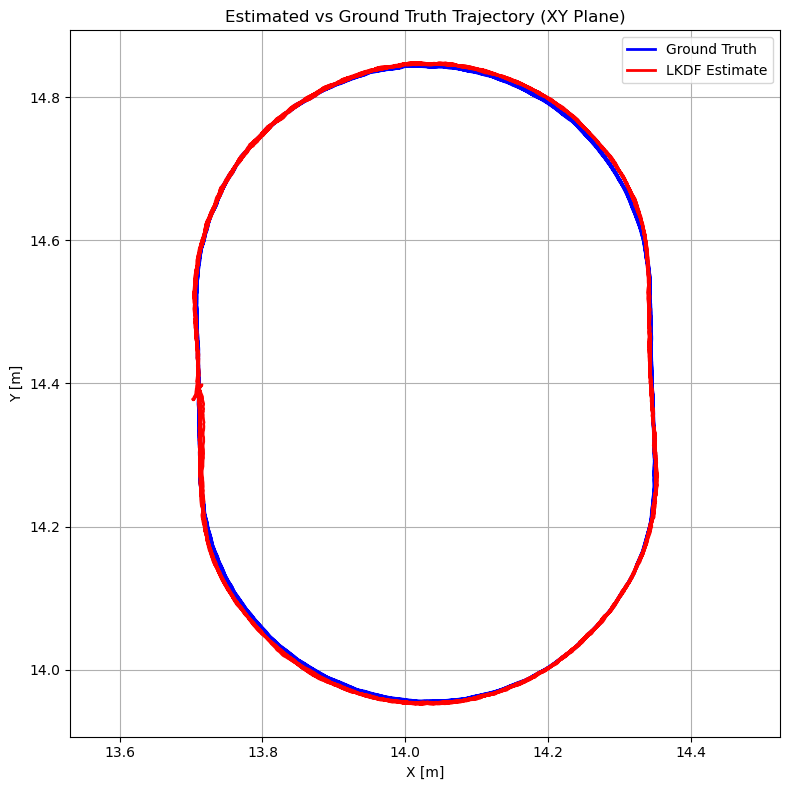

In [30]:
plt.figure(figsize=(8,8))

# Ground Truth
plt.plot(
    gtrue["X [m]"],
    gtrue["Y [m]"],
    linewidth=2,
    color='blue',
    label='Ground Truth')

# LKDF Estimate
plt.plot(
    estimates[:,0],
    estimates[:,1],
    linewidth=2,
    color='red',
    label='LKDF Estimate')

plt.xlabel("X [m]")
plt.ylabel("Y [m]")

plt.title("Estimated vs Ground Truth Trajectory (XY Plane)")

plt.axis('equal')
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig("Figures/LKDF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

- **The estimated trajectory closely follows the ground truth throughout the complete motion.**

- **Consequently, the modelling errors introduced by the constant-velocity model are corrected more effectively, particularly during the curved sections of the trajectory.**

- **Small residual deviations remain near the transition between straight and curved motion because the constant-velocity model cannot explicitly represent the centripetal acceleration associated with turning motion.**

- **These deviations arise from tangential prediction errors rather than numerical instability.**

- **The smooth and continuous trajectory, together with the absence of oscillations or divergence, confirms the stability and consistency of the implemented Linear Kalman Filter.**

## 2. Sensor Measurement vs Ground truth Trajectory 

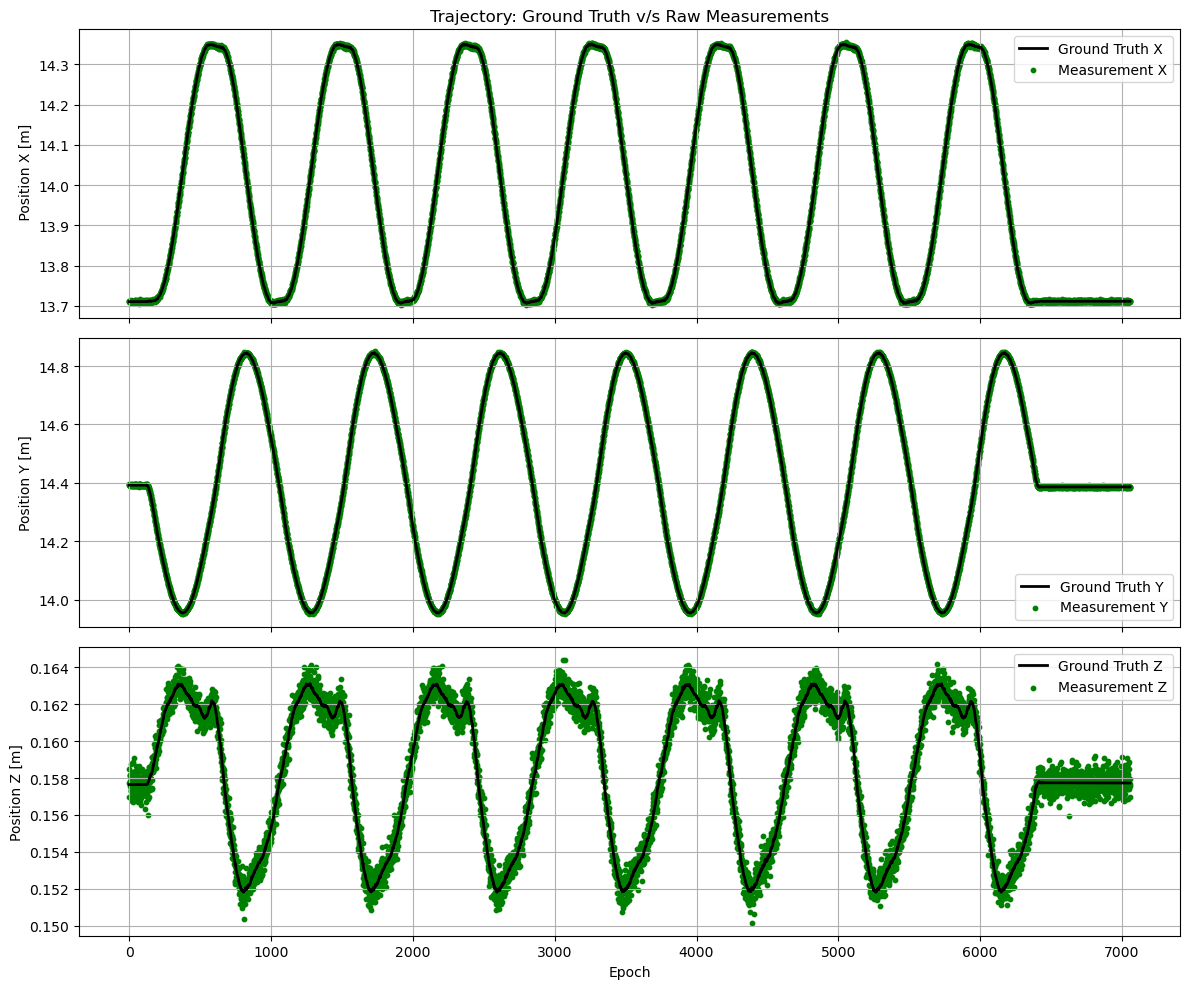

In [31]:
epochs = np.arange(len(obsrv))

fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# X Component
ax[0].plot(epochs,
    X_gtrue,
    color="black",
    linewidth=2,
    label="Ground Truth X")

ax[0].scatter(epochs,
    obsrv["X_obsrv_cart"],
    color="green",
    s=10,
    label="Measurement X")

ax[0].set_ylabel(" Position X [m]")
ax[0].set_title("Trajectory: Ground Truth v/s Raw Measurements")
ax[0].legend()
ax[0].grid(True)

# Y Component
ax[1].plot(epochs,
    Y_gtrue,
    color="black",
    linewidth=2,
    label="Ground Truth Y")

ax[1].scatter(epochs,
    obsrv["Y_obsrv_cart"],
    color="green",
    s=10,
    label="Measurement Y")

ax[1].set_ylabel("Position Y [m]")
ax[1].legend()
ax[1].grid(True)

# Z Component
ax[2].plot(epochs,
    Z_gtrue,
    color="black",
    linewidth=2,
    label="Ground Truth Z")

ax[2].scatter(epochs,
    obsrv["Z_obsrv_cart"],
    color="green",
    s=10,
    label="Measurement Z")

ax[2].set_ylabel("Position Z [m]")
ax[2].set_xlabel("Epoch")
ax[2].legend()
ax[2].grid(True)

plt.tight_layout()
plt.show()

- **This graph was plotted to show that the measurement from the sensor is high quality data as we can observe the X and Y components of the measurement data(green) closely overlaps the ground truth(black) indicating that the sensor data is already high quality and errors are less.**
- **The Z component scatters as it depends on the vertical angle/Zenith angle which is sensitive to small angular errors.**

## 3.Reference 3D Velocity Computation

The reference 3D velocity was derived from the ground-truth position trajectory using **numerical differentiation**. Since the dataset does not provide ground-truth velocity measurements, the reference velocities were obtained by numerically differentiating the ground-truth position using the sampling interval dt. The NumPy `gradient()` function was employed, which computes the derivative using the **central difference method** for interior data points and **first-order forward and backward differences** at the trajectory boundaries.

Given the ground-truth position components $X_{\mathrm{gtrue}}$, $Y_{\mathrm{gtrue}}$, and $Z_{\mathrm{gtrue}}$, the reference velocity components are obtained as

$$
V_{x,\mathrm{ref}}
=
\frac{dX_{\mathrm{gtrue}}}{dt},
$$

$$
V_{y,\mathrm{ref}}
=
\frac{dY_{\mathrm{gtrue}}}{dt},
$$

$$
V_{z,\mathrm{ref}}
=
\frac{dZ_{\mathrm{gtrue}}}{dt},
$$

where $dt$ is the constant sampling interval between consecutive measurements.

For the interior samples, the derivative is approximated using the central difference formula

$$
\frac{df}{dt}\Bigg|_{i}
\approx
\frac{f_{i+1}-f_{i-1}}{2dt},
\qquad i=2,\ldots,N-1.
$$

At the first and last samples, the derivative is computed using first-order forward and backward difference approximations, respectively,

$$
\frac{df}{dt}\Bigg|_{1}
\approx
\frac{f_{2}-f_{1}}{dt},
$$

$$
\frac{df}{dt}\Bigg|_{N}
\approx
\frac{f_{N}-f_{N-1}}{dt}.
$$

This numerical differentiation method provides a stable and accurate estimate of the reference velocity while preserving the same sampling rate as the ground-truth position trajectory.

In [32]:
#compuatation of reference velocity

Vx_ref = np.gradient(X_gtrue, dt)

Vy_ref = np.gradient(Y_gtrue, dt)

Vz_ref = np.gradient(Z_gtrue, dt)


## 4. Component wise Absolute deviation between estimated and ground truth 3D position over time

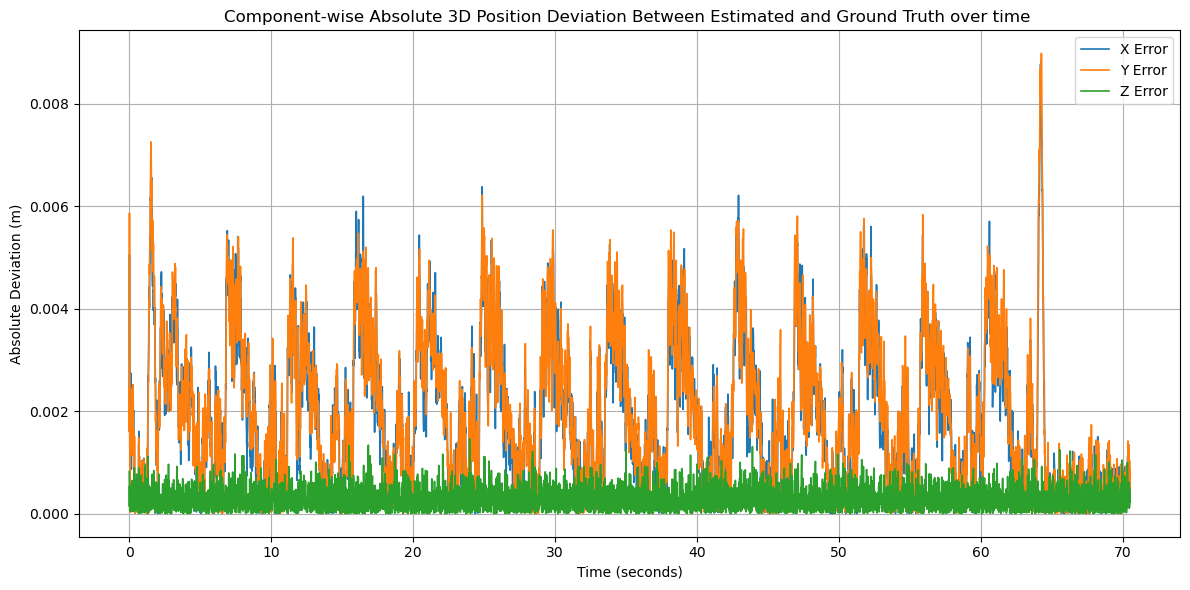

COMPONENT-WISE ABSOLUTE POSITION DEVIATION
Maximum Absolute X Deviation (m) : 0.008775092512
Maximum Absolute Y Deviation (m) : 0.008985439721
Maximum Absolute Z Deviation (m) : 0.001461195810

Mean Absolute X Deviation (m)    : 0.001885256098
Mean Absolute Y Deviation (m)    : 0.001940259760
Mean Absolute Z Deviation (m)    : 0.000287059193


In [33]:
# Absolute deviation
abs_error_x = np.abs(X_est - X_gtrue)
abs_error_y = np.abs(Y_est - Y_gtrue)
abs_error_z = np.abs(Z_est - Z_gtrue)

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    abs_error_x,
    linewidth=1.2,
    label="X Error")

plt.plot(
    time_inseconds,
    abs_error_y,
    linewidth=1.2,
    label="Y Error")

plt.plot(
    time_inseconds,
    abs_error_z,
    linewidth=1.2,
    label="Z Error")

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Deviation (m)")
plt.title("Component-wise Absolute 3D Position Deviation Between Estimated and Ground Truth over time ")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig("Figures/LKDF_Position_Absolute_deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*65)
print("COMPONENT-WISE ABSOLUTE POSITION DEVIATION")
print("="*65)

print(f"Maximum Absolute X Deviation (m) : {np.max(abs_error_x):.12f}")
print(f"Maximum Absolute Y Deviation (m) : {np.max(abs_error_y):.12f}")
print(f"Maximum Absolute Z Deviation (m) : {np.max(abs_error_z):.12f}")

print()

print(f"Mean Absolute X Deviation (m)    : {np.mean(abs_error_x):.12f}")
print(f"Mean Absolute Y Deviation (m)    : {np.mean(abs_error_y):.12f}")
print(f"Mean Absolute Z Deviation (m)    : {np.mean(abs_error_z):.12f}")

print("="*65)

- **The X- and Y-direction errors are larger than the Z-direction error throughout the trajectory because the majority of the robot's motion occurs in the horizontal (X-Y) plane.**
- **During the curved sections of the track, the robot continuously changes its direction of motion, introducing centripetal acceleration. Since the implemented LKDF is based on a constant-velocity motion model, these turning accelerations are not explicitly modelled. As a result, slightly larger prediction errors occur in the X and Y directions before the measurements correct the estimate.**
- **As the vertical velocity remains nearly constant and the vertical acceleration is negligible, the assumptions of the constant-velocity motion model are well satisfied in the Z direction, resulting in consistently small deviations.**
- **Several sharp peaks are observed in the X and Y error curves. These errors quickly returns to a low level after each peak which clearly demonstrates the recursive nature of the linear kalman filter.**
- **At every measurement epoch, the prediction is updated using the new total station observation, allowing the filter to continuously correct its previous estimate and prevent the error from accumulating over time.**


## 5. Component wise Absolute deviation between estimated and ground truth 3D velocity over time

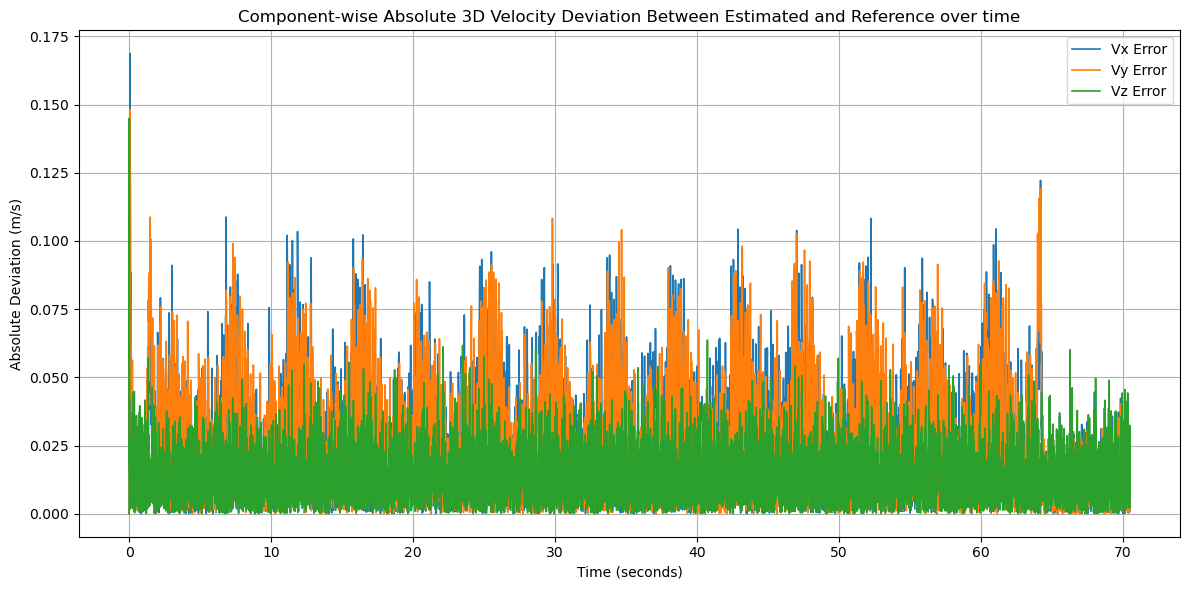

COMPONENT-WISE ABSOLUTE VELOCITY DEVIATION
Maximum Absolute Vx Deviation (m/s) : 0.168781463990
Maximum Absolute Vy Deviation (m/s) : 0.148243101838
Maximum Absolute Vz Deviation (m/s) : 0.144964777718

Mean Absolute Vx Deviation (m/s)    : 0.025326741667
Mean Absolute Vy Deviation (m/s)    : 0.025381922791
Mean Absolute Vz Deviation (m/s)    : 0.013938639767


In [34]:
# Component-wise Absolute Deviation for 3D Velocity

# Absolute deviation
abs_error_vx = np.abs(Vx_est - Vx_ref)
abs_error_vy = np.abs(Vy_est - Vy_ref)
abs_error_vz = np.abs(Vz_est - Vz_ref)

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    abs_error_vx,
    linewidth=1.2,
    label="Vx Error")

plt.plot(
    time_inseconds,
    abs_error_vy,
    linewidth=1.2,
    label="Vy Error")

plt.plot(
    time_inseconds,
    abs_error_vz,
    linewidth=1.2,
    label="Vz Error")

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Deviation (m/s)")
plt.title("Component-wise Absolute 3D Velocity Deviation Between Estimated and Reference over time")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/LKDF_Velocity_Absolute_deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()


print("="*65)
print("COMPONENT-WISE ABSOLUTE VELOCITY DEVIATION")
print("="*65)

print(f"Maximum Absolute Vx Deviation (m/s) : {np.max(abs_error_vx):.12f}")
print(f"Maximum Absolute Vy Deviation (m/s) : {np.max(abs_error_vy):.12f}")
print(f"Maximum Absolute Vz Deviation (m/s) : {np.max(abs_error_vz):.12f}")

print()

print(f"Mean Absolute Vx Deviation (m/s)    : {np.mean(abs_error_vx):.12f}")
print(f"Mean Absolute Vy Deviation (m/s)    : {np.mean(abs_error_vy):.12f}")
print(f"Mean Absolute Vz Deviation (m/s)    : {np.mean(abs_error_vz):.12f}")

print("="*65)

- **The absolute velocity deviation represents the difference between the estimated velocity obtained from the Linear Kalman Filter and the reference velocity at each measurement epoch.**
- **The velocity errors in the X and Y directions are consistently larger than those in the Z direction as the robot moves within the horizontal plane and during curved motion, the direction of the velocity vector changes continuously due to centripetal acceleration.**
- **Whereas the Z-direction velocity error remains comparatively smaller and more stable throughout the experiment.**
- **Several transient peaks are observed in the X and Y velocity errors. These peaks correspond to sections where the target enters or exits curved portions of the trajectory.**
- **At these locations, the actual velocity direction changes rapidly as the prediction model initially assumes that the previous velocity continues unchanged but the subsequent measurement update corrects this mismatch, causing the error to decrease rapidly after each peak.**
- **The absence of continuously increasing errors demonstrates that the recursive measurement-update mechanism effectively compensates for the modelling errors introduced by the constant-velocity assumption, maintaining stable velocity estimation.**

## 7. Component Wise Cumulative RMSE for 3D position over time


The component-wise cumulative Root Mean Square Error (RMSE) for the 3D position is computed separately for each Cartesian coordinate ($X$, $Y$, and $Z$). At each time step $k$, the RMSE is evaluated using all estimation errors accumulated from the first sample to the last sample, allowing the convergence and stability of the filter to be assessed over time.

For the $X$-component, the cumulative RMSE is given by:

$$
\mathrm{RMSE}_{X}(k)
=
\sqrt{
\frac{1}{k}
\sum_{i=1}^{k}
\left(X_{\mathrm{est},i}-X_{\mathrm{gtrue},i}\right)^2
}
$$

Similarly, the cumulative RMSE for the $Y$ and $Z$ components is computed as

$$
\mathrm{RMSE}_{Y}(k)
=
\sqrt{
\frac{1}{k}
\sum_{i=1}^{k}
\left(Y_{\mathrm{est},i}-Y_{\mathrm{gtrue},i}\right)^2
}
$$

$$
\mathrm{RMSE}_{Z}(k)
=
\sqrt{
\frac{1}{k}
\sum_{i=1}^{k}
\left(Z_{\mathrm{est},i}-Z_{\mathrm{gtrue},i}\right)^2
}
$$

POSITION RMSE
RMSE X (m) : 0.002355350105
RMSE Y (m) : 0.002421060196
RMSE Z (m) : 0.000359476885


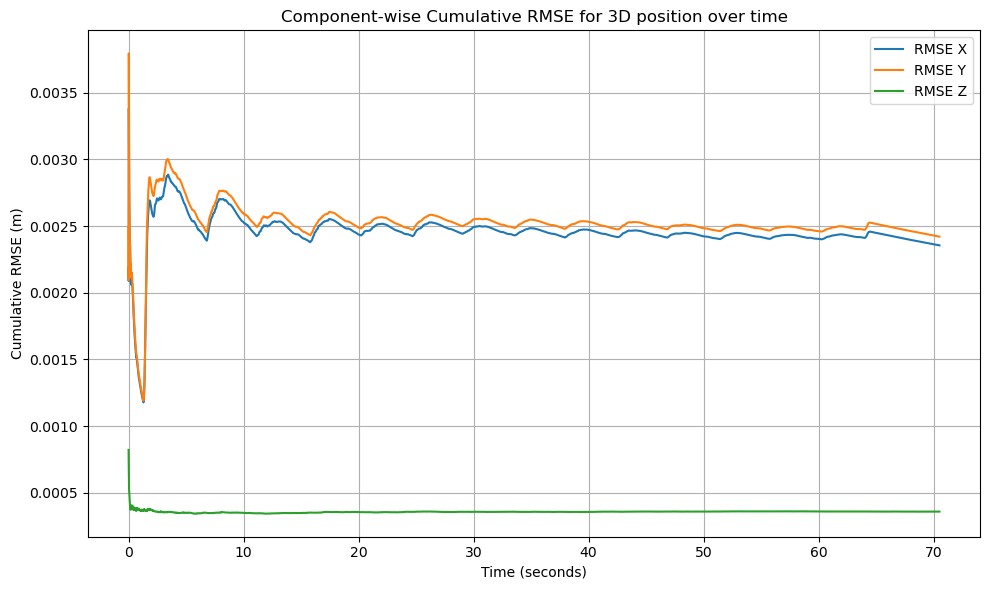

In [35]:
# Component-wise RMSE

rmse_x = np.sqrt(np.mean((X_est - X_gtrue)**2))
rmse_y = np.sqrt(np.mean((Y_est - Y_gtrue)**2))
rmse_z = np.sqrt(np.mean((Z_est - Z_gtrue)**2))

print("=" * 60)
print("POSITION RMSE")
print("=" * 60)
print(f"RMSE X (m) : {rmse_x:.12f}")
print(f"RMSE Y (m) : {rmse_y:.12f}")
print(f"RMSE Z (m) : {rmse_z:.12f}")

N = len(obsrv)

cum_rmse_x = np.zeros(N)
cum_rmse_y = np.zeros(N)
cum_rmse_z = np.zeros(N)

for k in range(N):

    cum_rmse_x[k] = np.sqrt(
        np.mean((X_est[:k+1] - X_gtrue[:k+1])**2))

    cum_rmse_y[k] = np.sqrt(
        np.mean((Y_est[:k+1] - Y_gtrue[:k+1])**2))

    cum_rmse_z[k] = np.sqrt(
        np.mean((Z_est[:k+1] - Z_gtrue[:k+1])**2))

plt.figure(figsize=(10,6))

plt.plot(time_inseconds, cum_rmse_x, label="RMSE X")
plt.plot(time_inseconds, cum_rmse_y, label="RMSE Y")
plt.plot(time_inseconds, cum_rmse_z, label="RMSE Z")

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Component-wise Cumulative RMSE for 3D position over time")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/LKDF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()


- **The component wise cumulative RMSE combines the errors from all previous epochs and therefore represents the overall estimation accuracy of the filter as it progresses through time for poistion in X,Y and Z direction.**
- **The X- and Y-direction RMSE curves initially fluctuate before gradually converging to nearly constant values as during the first few measurement epochs, the filter has limited information about the robot's motion and an initial covariance that reflects uncertainty in the state estimate.**
- **As additional measurements are incorporated recursively, the filter continuously refines both the state estimate and its covariance, causing the cumulative RMSE to stabilize.**
- **As the vertical velocity remains nearly constant and the vertical acceleration is negligible, the assumptions of the constant-velocity motion model are well satisfied in the Z direction, resulting in consistently small prediction errors and reduced RMSE values.**

## 8. Overall 3D position RMSE over time ( Computed for Easier Comparison)
The overall 3D position Root Mean Square Error (RMSE) provides a single measure of the estimation accuracy by combining the errors in all three Cartesian coordinates. It is computed from the Euclidean position error between the estimated and ground-truth positions over the entire trajectory.

$$
\mathrm{RMSE}_{3D}
=
\sqrt{
\frac{1}{N}
\sum_{i=1}^{N}
\left[
\left(X_{\mathrm{est},i}-X_{\mathrm{gtrue},i}\right)^2
+
\left(Y_{\mathrm{est},i}-Y_{\mathrm{gtrue},i}\right)^2
+
\left(Z_{\mathrm{est},i}-Z_{\mathrm{gtrue},i}\right)^2
\right]
}
$$

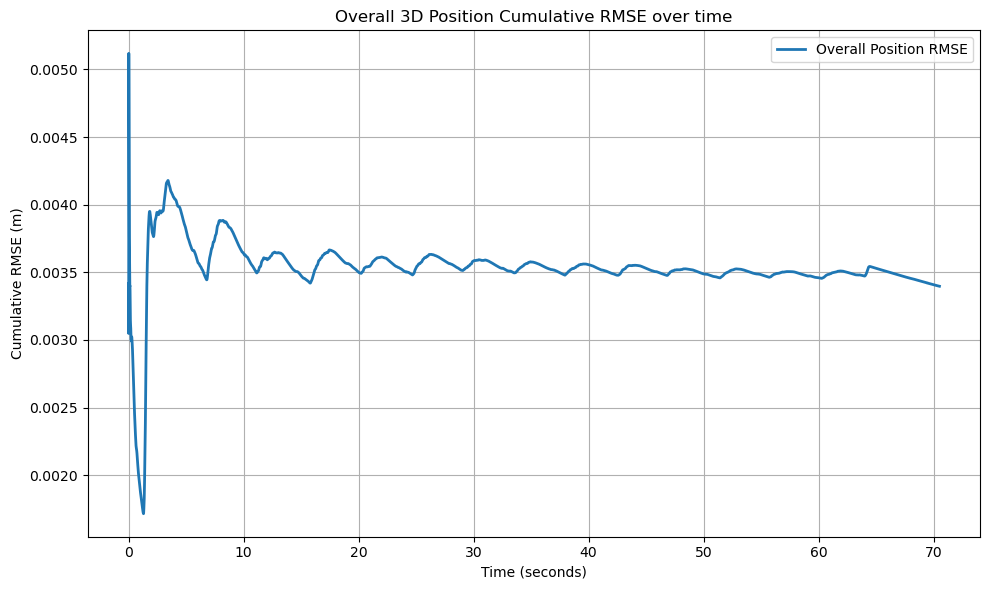

Overall 3D Position RMSE (m) : 0.003396826492


In [36]:
# Cumulative Overall 3D Position RMSE
N = len(obsrv)

cum_overall_rmse = np.zeros(N)

for k in range(N):

    error = np.sqrt(
        (X_est[:k+1] - X_gtrue[:k+1])**2 +
        (Y_est[:k+1] - Y_gtrue[:k+1])**2 +
        (Z_est[:k+1] - Z_gtrue[:k+1])**2)

    cum_overall_rmse[k] = np.sqrt(np.mean(error**2))

plt.figure(figsize=(10,6))

plt.plot(
    time_inseconds,
    cum_overall_rmse,
    linewidth=2,
    label="Overall Position RMSE")

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m)")
plt.title("Overall 3D Position Cumulative RMSE over time")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/LKDF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()


# Overall 3D Position Error
position_error = np.sqrt(
    (X_est - X_gtrue)**2 +
    (Y_est - Y_gtrue)**2 +
    (Z_est - Z_gtrue)**2)

# Overall 3D Position RMSE
overall_position_rmse = np.sqrt(np.mean(position_error**2))

print("="*60)
print(f"Overall 3D Position RMSE (m) : {overall_position_rmse:.12f}")
print("="*60)

## 9. Component wise Cumulative 3D velocity RMSE over time

VELOCITY RMSE
RMSE Vx (m/s) : 0.032617207916
RMSE Vy (m/s) : 0.032792058048
RMSE Vz (m/s) : 0.017478466222


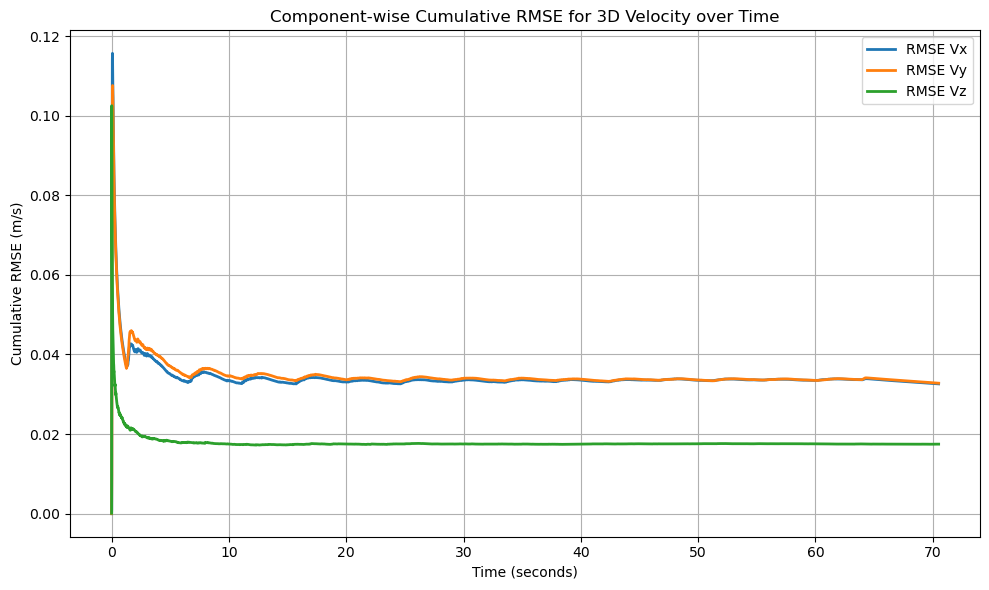

In [37]:
# Component-wise Velocity RMSE

rmse_vx = np.sqrt(np.mean((Vx_est - Vx_ref)**2))
rmse_vy = np.sqrt(np.mean((Vy_est - Vy_ref)**2))
rmse_vz = np.sqrt(np.mean((Vz_est - Vz_ref)**2))

print("="*60)
print("VELOCITY RMSE")
print("="*60)
print(f"RMSE Vx (m/s) : {rmse_vx:.12f}")
print(f"RMSE Vy (m/s) : {rmse_vy:.12f}")
print(f"RMSE Vz (m/s) : {rmse_vz:.12f}")
print("="*60)

N = len(obsrv)

cum_rmse_vx = np.zeros(N)
cum_rmse_vy = np.zeros(N)
cum_rmse_vz = np.zeros(N)

for k in range(N):

    cum_rmse_vx[k] = np.sqrt(
        np.mean((Vx_est[:k+1] - Vx_ref[:k+1])**2))

    cum_rmse_vy[k] = np.sqrt(
        np.mean((Vy_est[:k+1] - Vy_ref[:k+1])**2))

    cum_rmse_vz[k] = np.sqrt(
        np.mean((Vz_est[:k+1] - Vz_ref[:k+1])**2))

plt.figure(figsize=(10,6))

plt.plot(time_inseconds, cum_rmse_vx, linewidth=2, label="RMSE Vx")
plt.plot(time_inseconds, cum_rmse_vy, linewidth=2, label="RMSE Vy")
plt.plot(time_inseconds, cum_rmse_vz, linewidth=2, label="RMSE Vz")

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Component-wise Cumulative RMSE for 3D Velocity over Time")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/LKDF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

- **The figure presents the component wise cumulative Root Mean Square Error of the estimated velocity components in the X, Y, and Z directions over the complete trajectory which tells us overall average velocity estimation error from the beginning of the experiment up to each measurement epoch.**
- **All three velocity RMSE curves exhibit a large initial transient followed by gradual convergence to nearly constant values.**
- **At the beginning of the estimation process, the velocity states are initialized with limited prior information, while the filter possesses relatively high initial uncertainty. As recursive prediction and measurement updates are performed, the filter continuously refines the velocity estimates, causing the RMSE to decrease and eventually stabilize.**
- **The X- and Y-direction velocity RMSE values remain consistently larger than the Z-direction RMSE throughout the trajectory as the robot predominantly moves within the horizontal plane, where continuous changes in the direction of motion introduce centripetal acceleration.**
- **The Z-direction velocity RMSE converges to a significantly smaller value as the assumptions of the constant-velocity model are well satisfied in the Z direction, enabling more accurate recursive velocity estimation.**
- **No increasing trend is observed throughout the trajectory, indicating that the recursive estimation process successfully prevents the accumulation of velocity estimation errors and maintains stable dynamic performance.**

## 10. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

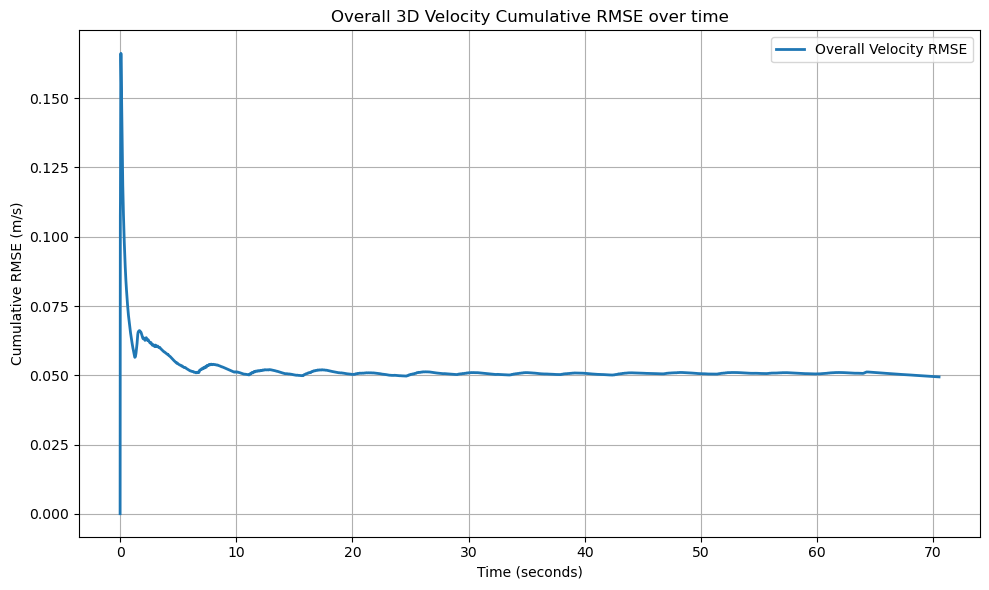

Overall 3D Velocity RMSE (m/s) : 0.049443888447


In [38]:
cum_overall_velocity_rmse = np.zeros(N)

for k in range(N):

    velocity_error = np.sqrt(
        (Vx_est[:k+1] - Vx_ref[:k+1])**2 +
        (Vy_est[:k+1] - Vy_ref[:k+1])**2 +
        (Vz_est[:k+1] - Vz_ref[:k+1])**2)

    cum_overall_velocity_rmse[k] = np.sqrt(
        np.mean(velocity_error**2))

plt.figure(figsize=(10,6))

plt.plot(
    time_inseconds,
    cum_overall_velocity_rmse,
    linewidth=2,
    label="Overall Velocity RMSE")

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Overall 3D Velocity Cumulative RMSE over time")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/LKDF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()


velocity_error = np.sqrt(
    (Vx_est - Vx_ref)**2 +
    (Vy_est - Vy_ref)**2 +
    (Vz_est - Vz_ref)**2)

overall_velocity_rmse = np.sqrt(np.mean(velocity_error**2))

print("="*60)
print(f"Overall 3D Velocity RMSE (m/s) : {overall_velocity_rmse:.12f}")
print("="*60)

## 11. Sensor Measurement Component wise and overall RMSE values (for comparison)


In [39]:
# COMPONENT-WISE SENSOR POSITION RMSE

rmse_sensor_x = np.sqrt(np.mean((X_obsrv - X_gtrue)**2))
rmse_sensor_y = np.sqrt(np.mean((Y_obsrv - Y_gtrue)**2))
rmse_sensor_z = np.sqrt(np.mean((Z_obsrv - Z_gtrue)**2))

print("="*60)
print("COMPONENT-WISE SENSOR POSITION RMSE")
print("="*60)
print(f"RMSE X (m) : {rmse_sensor_x:.12f}")
print(f"RMSE Y (m) : {rmse_sensor_y:.12f}")
print(f"RMSE Z (m) : {rmse_sensor_z:.12f}")
print("="*60)

# OVERALL 3D SENSOR POSITION RMSE

sensor_position_error = np.sqrt(
    (X_obsrv - X_gtrue)**2 +
    (Y_obsrv - Y_gtrue)**2 +
    (Z_obsrv - Z_gtrue)**2)

overall_sensor_rmse = np.sqrt(np.mean(sensor_position_error**2))

print("="*60)
print(f"Overall 3D Sensor position RMSE (m) : {overall_sensor_rmse:.12f}")
print("="*60)


# Sensor Velocity from Cartesian Measurements

vx_sensor = np.gradient(X_obsrv, dt)
vy_sensor = np.gradient(Y_obsrv, dt)
vz_sensor = np.gradient(Z_obsrv, dt)

# COMPONENT-WISE SENSOR VELOCITY RMSE

rmse_sensor_vx = np.sqrt(np.mean((vx_sensor - Vx_ref)**2))
rmse_sensor_vy = np.sqrt(np.mean((vy_sensor - Vy_ref)**2))
rmse_sensor_vz = np.sqrt(np.mean((vz_sensor - Vz_ref)**2))

print("="*60)
print("COMPONENT-WISE SENSOR VELOCITY RMSE")
print("="*60)
print(f"RMSE Vx (m/s) : {rmse_sensor_vx:.12f}")
print(f"RMSE Vy (m/s) : {rmse_sensor_vy:.12f}")
print(f"RMSE Vz (m/s) : {rmse_sensor_vz:.12f}")
print("="*60)

# OVERALL 3D SENSOR VELOCITY RMSE

sensor_velocity_error = np.sqrt(
    (vx_sensor - Vx_ref)**2 +
    (vy_sensor - Vy_ref)**2 +
    (vz_sensor - Vz_ref)**2)

overall_sensor_velocity_rmse = np.sqrt(
    np.mean(sensor_velocity_error**2))


print(f"Overall 3D Sensor Velocity RMSE (m/s) : {overall_sensor_velocity_rmse:.12f}")
print("="*60)

COMPONENT-WISE SENSOR POSITION RMSE
RMSE X (m) : 0.001840695495
RMSE Y (m) : 0.001885843638
RMSE Z (m) : 0.000490385400
Overall 3D Sensor position RMSE (m) : 0.002680493233
COMPONENT-WISE SENSOR VELOCITY RMSE
RMSE Vx (m/s) : 0.129803363954
RMSE Vy (m/s) : 0.133420730580
RMSE Vz (m/s) : 0.034767712281
Overall 3D Sensor Velocity RMSE (m/s) : 0.189364195294


- **The computed RMSE values represent the accuracy of the raw sensor measurements before any filtering is applied. These values are used as the baseline performance of the measurement system and are used to evaluate the improvement achieved by the Filter.**

# Improvement Analysis Compared to Sensor Measurements

The RMSE improvement analysis was performed to quantify how much the implemented Kalman filter improves the estimation accuracy relative to the original sensor measurements. While the RMSE values indicate the absolute estimation error, the improvement percentage expresses the reduction or increase in error as a percentage, making it easier to compare the performance of different filters and different state components.

The percentage improvement is calculated separately for each state component using

$$
\text{Improvement}(\%)=
\frac{\mathrm{RMSE}_{\mathrm{sensor}}-\mathrm{RMSE}_{\mathrm{filter}}}
{\mathrm{RMSE}_{\mathrm{sensor}}}
\times100
$$

where

- $\mathrm{RMSE}_{\mathrm{sensor}}$ represents the RMSE of the original sensor measurements.
- $\mathrm{RMSE}_{\mathrm{filter}}$ represents the RMSE of the estimated values obtained from the Kalman filter.

Similarly, the overall three-dimensional position improvement is computed as

$$
\text{Overall Position Improvement}(\%)=
\frac{\mathrm{RMSE}_{\mathrm{sensor}}^{3D}-\mathrm{RMSE}_{\mathrm{filter}}^{3D}}
{\mathrm{RMSE}_{\mathrm{sensor}}^{3D}}
\times100
$$

and the overall three-dimensional velocity improvement is computed using

$$
\text{Overall Velocity Improvement}(\%)=
\frac{\mathrm{RMSE}_{\mathrm{sensor}}^{3D}-\mathrm{RMSE}_{\mathrm{filter}}^{3D}}
{\mathrm{RMSE}_{\mathrm{sensor}}^{3D}}
\times100.
$$

The analysis was performed for the Linear Kalman Filter using a process noise standard deviation of $\sigma_a = 2.5~\mathrm{m/s^2}$.

In [40]:
# POSITION RMSE IMPROVEMENT

improvement_x = ((rmse_sensor_x - rmse_x) / rmse_sensor_x) * 100
improvement_y = ((rmse_sensor_y - rmse_y) / rmse_sensor_y) * 100
improvement_z = ((rmse_sensor_z - rmse_z) / rmse_sensor_z) * 100

overall_position_improvement = (
    (overall_sensor_rmse - overall_position_rmse)
    / overall_sensor_rmse
) * 100

print("="*65)
print("POSITION RMSE IMPROVEMENT")
print("="*65)

print(f"Improvement X (%)          : {improvement_x:.2f}")
print(f"Improvement Y (%)          : {improvement_y:.2f}")
print(f"Improvement Z (%)          : {improvement_z:.2f}")
print(f"Overall Position Improvement (%) : {overall_position_improvement:.2f}")

print("="*65)

# VELOCITY RMSE IMPROVEMENT

improvement_vx = ((rmse_sensor_vx - rmse_vx) / rmse_sensor_vx) * 100
improvement_vy = ((rmse_sensor_vy - rmse_vy) / rmse_sensor_vy) * 100
improvement_vz = ((rmse_sensor_vz - rmse_vz) / rmse_sensor_vz) * 100

overall_velocity_improvement = (
    (overall_sensor_velocity_rmse - overall_velocity_rmse)
    / overall_sensor_velocity_rmse) * 100

print("="*65)
print("VELOCITY RMSE IMPROVEMENT")
print("="*65)

print(f"Improvement Vx (%)         : {improvement_vx:.2f}")
print(f"Improvement Vy (%)         : {improvement_vy:.2f}")
print(f"Improvement Vz (%)         : {improvement_vz:.2f}")
print(f"Overall Velocity Improvement (%) : {overall_velocity_improvement:.2f}")

print("="*65)

POSITION RMSE IMPROVEMENT
Improvement X (%)          : -27.96
Improvement Y (%)          : -28.38
Improvement Z (%)          : 26.70
Overall Position Improvement (%) : -26.72
VELOCITY RMSE IMPROVEMENT
Improvement Vx (%)         : 74.87
Improvement Vy (%)         : 75.42
Improvement Vz (%)         : 49.73
Overall Velocity Improvement (%) : 73.89


- **The obtained results indicate contrasting behaviour for the position and velocity states.**

- **For the position components, the filter produced improvement values of −27.96%, −28.38%, and 26.70% for the X, Y, and Z directions, respectively, resulting in an overall position improvement of −26.72%.**
- **The negative improvement observed in the horizontal components does not imply instability of the filter. Instead, it shows that the total station already provides highly accurate millimetre-level position measurements. Hence, there is limited scope for further reducing the position error.**
- **Due to the curved motion, the constant-velocity motion model introduces a small prediction lag as it cannot explicitly represent the centripetal acceleration which is subsequently corrected by the recursive measurement updates. However, the slight prediction lag increases the horizontal position RMSE relative to the already highly accurate sensor measurements.**
- **In contrast, the vertical motion experiences negligible acceleration and closely satisfies the assumptions of the constant-velocity model, allowing the filter to reduce the Z-direction position error.**


- **The velocity improvement results exhibit a substantially different behaviour where improvements of 74.87%, 75.42%, and 49.73% were achieved for the X, Y, and Z velocity components, respectively, resulting in an overall velocity improvement of 73.89%.**

- **Unlike position, velocity is not directly measured by the total station but is recursively estimated from the motion model and successive position observations.**

- **Consequently, the recursive filtering process significantly reduces the uncertainty associated with the velocity estimates. The large improvement observed in the horizontal velocity components demonstrates that the selected process-noise parameter, $\sigma_a = 2.5~\mathrm{m/s^2}$, provides an appropriate balance between the prediction model and the measurement update, allowing the filter to effectively compensate for the unmodelled turning dynamics while maintaining stable recursive estimation.**

- **Overall, the improvement analysis demonstrates the ability of Linear Kalman Filter to provide highly accurate and dynamically consistent velocity estimates while preserving millimetre-level position accuracy. Although the horizontal position RMSE is slightly larger than that of the raw total station measurements, the filter successfully estimates the complete system state, suppresses measurement noise, maintains recursive consistency, and substantially improves the estimation of unmeasured velocity states, thereby enhancing the overall dynamic state estimation performance.**

# DISCUSSIONS 

In the case of LKDF, discussions mainly included around selection of tuning parameters like process noise standard deviation (Sigma_a) and velocity variances of X, Z and Y direction in the initial covariance matrix(Q_xx).

## Process noise standard deviation selection

The process-noise standard deviation, denoted by $\sigma_a$, is an influential tuning parameter in all the kalman filters. **It represents the uncertainty associated with the assumed system dynamics and models the unknown acceleration that is not explicitly included in the constant-velocity motion model.**

Below is a detailed table which includes  both the componenet wise and overall position and velocity RMSE and the Mean Kalman gain in X, Y and Z component for different process noise standard deviation values.This table helps to explain why $\sigma_a = 2.5~\mathrm{m/s^2}$ was chosen as our process noise parameter throughout the filters.


#### Position Estimation Performance of the LKDF for Different Process Noise Standard Deviations

| **Process Noise $\sigma_a$ (m/s²)** | **Mean $K_x$** | **Mean $K_y$** | **Mean $K_z$** |  **RMSE X (m)** |  **RMSE Y (m)** |  **RMSE Z (m)** | **Overall 3D Position RMSE (m)** |
| :---------------------------------: | -------------: | -------------: | -------------: | --------------: | --------------: | --------------: | -------------------------------: |
|               **0.5**               |       0.209273 |       0.197901 |       0.364221 |     0.010487429 |     0.010853632 |     0.000289039 |                  **0.015095398** |
|               **2.0**               |       0.350680 |       0.326805 |       0.593436 |     0.002878968 |     0.002960850 |     0.000346528 |                  **0.004144294** |
|               **2.5**               |       0.376858 |       0.350261 |       0.633648 |     0.002355350 |     0.002421060 |     0.000359477 |                  **0.003396826** |
|               **21.0**              |       0.612687 |       0.568722 |       0.934471 | 0.000949424| 0.000980449 | 0.000462567 |                  **0.001441060**|



#### Velocity Estimation Performance of the LKDF for Different Process Noise Standard Deviations

| **Process Noise $\sigma_a$ (m/s²)** | **RMSE $V_x$ (m/s)** | **RMSE $V_y$ (m/s)** | **RMSE $V_z$ (m/s)** | **Overall 3D Velocity RMSE (m/s)** |
| :---------------------------------: | -------------------: | -------------------: | -------------------: | ---------------------------------: |
|               **0.5**               |          0.054117994 |          0.056227898 |          0.005853101 |                    **0.078259776** |
|               **2.0**               |          0.034231909 |          0.034487156 |          0.014888982 |                    **0.050821937** |
|               **2.5**               |          0.032617208 |          0.032792058 |          0.017478466 |                    **0.049443888** |
|               **21.0**              |      0.059568884 |      0.058252878 |      0.078710745 |                    **0.114617761** |


#### Justification 

- **The state prediction of the Linear Kalman Filter is based on the constant-velocity assumption, where the transition matrix assumes that the velocity remains constant between two consecutive measurement epochs.**
- However,we understood that the robot goes around the track 7 laps. So their are 2 curved sections and 2 straight path along the track in one lap. **And during all curved sections the robot undergoes turning motion along the curved sections,introducing centripetal acceleration that violates the constant velocity model as acceleration states are not represented in the model**.Hence the unmodelled acceleration is represented statistically through the process-noise covariance matrix Q_ww in this filter.
- **Consequently, the selection of $\sigma_a$ determines how much uncertainty is assigned to the prediction model and directly influences the recursive behaviour of the Kalman filter.**
- **If  $\sigma_a = 0.5~\mathrm{m/s^2}$ is choosen more weight is given to the prediction model compared to the sensor measuremnets.This can be understood by Mean Kalman gains in the table.**
- The process-noise covariance is proportional to $\sigma_a^2$, so increasing $\sigma_a$ enlarges the predicted covariance and the kalman gain. **Therefore, a smaller $\sigma_a$ produces a smaller predicted covariance and consequently a smaller Kalman gain, whereas a larger $\sigma_a$ produces a larger predicted covariance and a larger Kalman gain**.
- The Kalman gain determines the relative influence of the prediction model and the incoming observations during the recursive update.It reflects how the filter balances the model prediction and the measurements based on their estimated uncertainties. However it was not understood as a percentage calculation.

#### Behaviour of $\sigma_a=0.5~\mathrm{m/s^2}$

The primary process noise sandard deviation was selected as $\sigma_a=0.5~\mathrm{m/s^2}$ as we wanted to understand how the filter behaves for such a small value.The process-noise covariance remains relatively small, resulting in a smaller predicted covariance and consequently lower Kalman gains. From the table and comparing with the other kalman gains,**the smaller Kalman gain of $\sigma_a=0.5~\mathrm{m/s^2}$ causes the recursive estimator to rely more strongly on the prediction model. But since the prediction assumes constant velocity, the filter accurately follows the straight portions of the trajectory but struggles during the curved sections where the target experiences centripetal acceleration. Because this acceleration is not represented in the state model, tangential errors develop before the measurement update can correct them.**

#### Influence on position RMSE values
- **The X- and Y-direction position RMSE values are considerably larger than the Z-direction RMSE as the direction of motion changes continuously due to centripetal acceleration, while the constant-velocity model predicts that the robot continues travelling along its previous direction. As a result, the prediction introduces tangential position errors in the horizontal plane.**
- **Because the Kalman gain is relatively small, these prediction errors are only corrected gradually during the recursive measurement updates, producing the comparatively large X- and Y-direction RMSE values of approximately 10.5 mm.**
- **The Z-direction behaves differently as the robot experiences very little vertical motion, and the vertical velocity remains nearly constant. Consequently, the assumptions of the constant-velocity model are well satisfied in the vertical direction, resulting in a very small Z-direction RMSE of only 0.289 mm.**
- **The overall three-dimensional position RMSE of 15.10 mm therefore reflects the dominance of the horizontal estimation errors.This is why the X and Y RMSE are larger than Z for position in this filter.**

#### Influence on velocity RMSE values

- **The velocity RMSE exhibits a similar trend. The horizontal velocity components show the largest errors because the filter prediction assumes constant velocity whereas the robot experiences turning motion.**
- **The recursive corrections applied during the measurement update are insufficient to immediately compensate for these turning dynamics. Consequently, the horizontal velocity RMSE values remain relatively high, reaching approximately 0.054–0.056 m/s.**
- **In contrast, the vertical velocity component exhibits the smallest RMSE (0.00585 m/s). The vertical motion contains minimal acceleration and only slight variations in velocity, allowing the constant-velocity model to represent the vertical dynamics accurately.**
- **The overall three-dimensional velocity RMSE of 0.0783 m/s is therefore primarily governed by the horizontal velocity estimation errors rather than the vertical component.**


#### Behaviour of $\sigma_a=2~\mathrm{m/s^2}$
While comparing to the previous sigma_a value the new  value of $\sigma_a=2~\mathrm{m/s^2}$ increases the process-noise covariance which in turn increases the kalman gain.This can be seen in the table. **The larger Kalman gain indicates that the filter assigns greater confidence to the incoming measurements while still maintaining recursive prediction–correction estimation.As a result,the filter becomes more responsive to changes in the target motion, particularly during the curved sections of the trajectory where the constant-velocity model experiences tangential errors.**

#### Influence on Position RMSE values

| **Component**           | **RMSE (0.5)** | **RMSE (2.0)** | **Change** |
| :---------------------- | -------------: | -------------: | ---------: |
| **X**                   |    0.010487429 |    0.002878968 |    ↓ 72.6% |
| **Y**                   |    0.010853632 |    0.002960850 |    ↓ 72.7% |
| **Z**                   |    0.000289039 |    0.000346528 |    ↑ 19.9% |
| **Overall 3D Position** |    0.015095398 |    0.004144294 |    ↓ 72.5% |


The most **significant improvement occurs in the horizontal position components.** Increasing the Kalman gain allows the recursive measurement update to correct the tangential prediction errors much more effectively than in the $\sigma_a=0.5~\mathrm{m/s^2}$ case. Consequently, the X-direction RMSE decreases from 10.49 mm to 2.88 mm, while the Y-direction RMSE decreases from 10.85 mm to 2.96 mm, representing **improvements of approximately 73% in both directions.**

**Reason:This substantial improvement occurs because the larger process noise represents the uncertainty associated with the unmodelled centripetal acceleration experienced during turning better and rather than relying predominantly on the constant-velocity prediction, the filter now adapts more rapidly to the measured trajectory, significantly reducing the horizontal estimation error.**

The Z-direction exhibits a different behaviour where **RMSE increases slightly from 0.289 mm to 0.347 mm, corresponding to an increase of approximately 20%. This does not indicate poorer filtering performance but since the vertical motion already closely satisfies the constant-velocity assumption, the prediction errors are inherently very small.**

**Reason:Increasing the Kalman gain causes the filter to respond more strongly to the small measurement variations present in the total station observations, resulting in a slight increase in the vertical estimation error. Nevertheless, the absolute increase is only 0.058 mm, which remains negligible compared with the substantial reduction achieved in the horizontal position components**

Consequently, the overall three-dimensional position RMSE decreases from 15.10 mm to 4.14 mm, representing an overall improvement of approximately 72.5%.

#### Influence on Velocity RMSE values

| **Component**           | **RMSE (0.5)** | **RMSE (2.0)** | **Change** |
| :---------------------- | -------------: | -------------: | ---------: |
| **Vx**                  |    0.054117994 |    0.034231909 |    ↓ 36.8% |
| **Vy**                  |    0.056227898 |    0.034487156 |    ↓ 38.7% |
| **Vz**                  |    0.005853101 |    0.014888982 |     ↑ 154% |
| **Overall 3D Velocity** |    0.078259776 |    0.050821937 |    ↓ 35.1% |

- **In comparison with previous $\sigma_a=0.5~\mathrm{m/s^2}$ velocities, the estimation decreases as the larger process noise allows the filter to correct the horizontal velocity prediction errors more effectively during turning. Consequently, the X- and Y-direction velocity RMSE values decrease by approximately 37–39%, indicating improved estimation of the changing velocity direction.**

- **But the Z direction velocity RMSE drastically increases from 0.00585 m/s to 0.01489 m/s. Although this represents a large percentage increase, the interpretation is based on the absolute values rather than the percentage alone. The initial Z-direction velocity RMSE is extremely small; therefore, even a small absolute increase produces a large percentage change. This behaviour occurs because the larger Kalman gain allows additional measurement noise to influence the vertical velocity estimate, even though the vertical motion remains nearly constant throughout the experiment.**

- **Despite the increase in the vertical velocity RMSE, the substantial reductions achieved in the horizontal velocity components dominate the overall estimation performance. Consequently, the overall three-dimensional velocity RMSE decreases from 0.0783 m/s to 0.0508 m/s, corresponding to an improvement of approximately 35%.**


Overall, the results demonstrate that $\sigma_a=2~\mathrm{m/s^2}$ provides a much better balance between model prediction and measurement correction than $\sigma_a=0.5~\mathrm{m/s^2}$ , leading to
improved recursive estimation of robots motion while maintaining stable filter behaviour.

#### Trajectory Behaviour for Different Process Noise Values ($\sigma_a = 0.5$, $2.0$, and $2.5~\mathrm{m/s^2}$)

The estimated trajectories obtained using $\sigma_a=0.5$, $2$ and $2.5 ~\mathrm{m/s^2}$ demonstrate how the process-noise parameter influences the balance between the prediction model and the measurement update during recursive estimation. **Although all three configurations remain stable, their ability to follow the true trajectory differs considerably, particularly during the curved sections of the race track.**

**For  $\sigma_a=0.5 ~\mathrm{m/s^2}$ during the straight sections of the trajectory, the constant-velocity model closely represents the actual motion, resulting in smooth and accurate estimates. However, when the robot enters a curved section, its direction changes continuously due to centripetal acceleration producing tangential prediction errors and a noticeable offset during the curved sections**

**When it comes to  $\sigma_a=2~\mathrm{m/s^2}$ increasing the process-noise standard deviation
makes the filter more responsive to the measurements and corrects the tangential prediction errors more effectively than in the previous case. Hence the trajectory follows the ground truth more closely, particularly along the curved sections, and the horizontal position RMSE decreases substantially. However, small deviations are still observed near the transition between straight and curved motion. These deviations occur because the prediction model continues to assume constant velocity. Although the larger Kalman gain improves the correction of the prediction errors, the filter still requires one or more recursive updates before fully adapting to the change in motion direction. Therefore, slight trajectory offsets remain visible at the entry and exit of the curves.**

**However when $\sigma_a=2.5~\mathrm{m/s^2}$ is used the predicted covariance and Kalman gain increases. The recursive measurement update has a greater influence on the state estimate, allowing the filter to compensate more effectively for the unmodelled centripetal acceleration. Consequently, the trajectory follows the ground truth more closely, particularly during turning. We believe that it provides a much more balanced recursive estimation while also giving equal importance to weights and hence provides a better solution to tangential errors. This can be clearly seen in the kalman gain table showing the changes in RMSE values and its influence on measurement data and the prediction model.**


#### Behaviour of $\sigma_a=2.5~\mathrm{m/s^2}$

**Increasing the process-noise standard deviation further increases the kalman gain which enables the filter to respond more rapidly to the incoming measurements while preserving the recursive prediction–correction process. The prediction model still contributes significantly to the state estimate, but the measurement update becomes slightly more effective in compensating for the unmodelled turning dynamics reducing tangential errors.**

#### Influence on Position RMSE values

| **Component**           | **RMSE ((\sigma_a=2.0)) (m)** | **RMSE ((\sigma_a=2.5)) (m)** | **Improvement (%)** |
| :---------------------- | ----------------------------: | ----------------------------: | ------------------: |
| **X**                   |                   0.002878968 |                   0.002355350 |           **18.18** |
| **Y**                   |                   0.002960850 |                   0.002421060 |           **18.23** |
| **Z**                   |                   0.000346528 |                   0.000359477 |           **−3.74** |
| **Overall 3D Position** |                   0.004144294 |                   0.003396826 |           **18.03** |

- **The X- and Y-direction position RMSE values decrease by approximately 18%, indicating that the larger process noise enables the filter to compensate more effectively for the tangential prediction errors introduced during curved motion compared to $\sigma_a=2~\mathrm{m/s^2}$. Since the Kalman gain is slightly larger, the recursive measurement update corrects the prediction more rapidly whenever the robot changes direction.**
- **The Z-direction position RMSE exhibits a very small increase of approximately 3.7%.This increase is practically negligible and occurs because the vertical motion already satisfies the constant-velocity assumption very well. The slightly larger Kalman gain allows a small increase in the influence of measurement noise on the vertical estimate, producing a marginal increase in the Z-direction RMSE.**
- **Overall, the three-dimensional position RMSE decreases from **4.14 mm** to **3.40 mm**, confirming that $\sigma_a = 2.5~\mathrm{m/s^2}$ provides a more accurate position estimate than $\sigma_a = 2.0~\mathrm{m/s^2}$.**

#### Influence on Velocity RMSE values

| **Component**           | **RMSE ((\sigma_a=2.0)) (m/s)** | **RMSE ((\sigma_a=2.5)) (m/s)** | **Improvement (%)** |
| :---------------------- | ------------------------------: | ------------------------------: | ------------------: |
| **Vx**                  |                     0.034231909 |                     0.032617208 |            **4.72** |
| **Vy**                  |                     0.034487156 |                     0.032792058 |            **4.92** |
| **Vz**                  |                     0.014888982 |                     0.017478466 |          **−17.39** |
| **Overall 3D Velocity** |                     0.050821937 |                     0.049443888 |            **2.71** |

- **The horizontal velocity RMSE values decrease slightly wjich demonstrates that the larger Kalman gain enables the recursive filter to adapt more quickly to the changing direction of motion during curved sections.**
- **The Z-direction velocity RMSE increases from 0.0149 m/s to 0.0175 m/s, corresponding to an increase of approximately 17%. This increase is expected because the vertical motion remains nearly constant throughout the experiment. Increasing the process noise beyond the level required for the vertical dynamics allows slightly more measurement noise to influence the recursive velocity estimate. Nevertheless, the increase remains small compared with the improvements achieved in the horizontal components.**
- **The overall three-dimensional velocity RMSE decreases from 0.0508 m/s to 0.0494 m/s, indicating that the larger process-noise parameter provides a modest but consistent improvement in the overall velocity estimation performance.**

#### Behaviour of **$\sigma_a = 21~\mathrm{m/s^2}$.**

As a trial and error approach the $\sigma_a$ value was increased to 21. Consequently, the predicted covariance increases significantly, resulting in much larger Kalman gains and the **filter therefore placed considerably greater confidence in the incoming measurements and less confidence in the constant-velocity prediction model.**

**As a result, the position estimation improves substantially.** The X- and Y-direction position RMSE values decrease to 0.95 mm and 0.98 mm, respectively, producing the lowest overall three-dimensional position RMSE (1.44 mm) among all the process-noise values. 

**However, this improvement comes at the expense of the velocity estimation** Unlike position, velocity is not directly measured by the total station but is estimated recursively from the prediction model and successive position observations. Because the filter now relies much more heavily on the measurements, the prediction model contributes less to smoothing and maintaining temporal consistency. **Consequently, small variations and noise in the position measurements propagate into the velocity estimates, causing the velocity RMSE to increase significantly.** 

**Although it minimizes the position RMSE, it excessively prioritizes measurement tracking over recursive state prediction, resulting in poor velocity estimation and an imbalance between position and dynamic state accuracy. Therefore, this filter was not selected for the final implementation.**

## Overall Justification for selecting $\sigma_a = 2.5~\mathrm{m/s^2}$

- **Out of all the sigma_a values 2.5 was selected as we beileve it achieves the best balance between prediction and measurement and both contribute equally.**
- **This is proven with the above rmse values and trajectory estimation which closely follows the ground truth compared to other values.**
- **Another reason is the curved track which the robot travels.The trajectory produces modelling errors which can be corrected by this standard deviation.**
- **Further it reduces tangential error due to centripetal acceleration better compared to other values.**
- **It also provides better position and velocity RMSE values in X and Y directions compared to other values and slight increase in Z direction RMSE but it can be neglected as the robot commutes in the horizontal plane.**
- **Further the values ensures better balance between the prediction and mesurement is needed for other filters especially constrained filters so that the filter does not become dominant towards one side and also makes comparison easy and meaningful.**


#### Justification for Selection of Velocity Variances of Initial Covariance matrix

- **The initial velocity componenets for the Initial covaraiance matrix were not directly measured by the total station.**
- **Hence the initial velocities were not initialized to zero as it contained significant uncertainity.**
- **Similar to the sigma_a value we wanted the initial velocity variances of initial covariance matrix to be balanced because a smaller variance makes the filter overconnfident in the unknown initial velocities and a larger variance will allow the recursive filter to estimate the velocities progressively from the measurements.**
- **Hence the velocity variances were taken as 1 which provided better balance and estimation accuracy.**
  
### Selection of Design matrix
Discussions were done in choosing the design matrix as it was not also provided. The design matrix was selected to include only the position components because the total station directly measures the three-dimensional position coordinates $(X,\,Y,\,Z)$. The velocity components $(V_x,\,V_y,\,V_z)$ were not included in the observation model because they are not directly observed by the sensor. Instead, these states are estimated recursively by the kalman filter.

### Computational Time 
A low compuatational time of 1.639461 s with average Time per Epoch of 0.00023235 was obtained which showed the computational ease of LKDF.

## CONCLUSION

- **The Linear Kalman Filter converged successfully for all tested values of the process-noise standard deviation, indicating stable recursive state estimation. No divergence or numerical instability was observed throughout the estimation process.**
- **The state estimates became progressively more accurate as additional measurements were incorporated through the recursive prediction–correction cycle and the initial uncertainty in the velocity states was gradually reduced as the filter estimated the unknown velocities from successive position measurements.**
- **The constant-velocity model performed well during straight motion but introduced tangential prediction errors during turning.Increasing the process noise from $\sigma_a=0.5$ to $\sigma_a=2.5~\mathrm{m/s^2}$ improved the convergence towards the reference trajectory during curved motion**
- **A very large process noise ($\sigma_a=21~\mathrm{m/s^2}$) produced faster convergence of the position estimates but reduced the convergence quality of the velocity estimates because the filter became excessively measurement-driven.**
- **The mean absolute position deviation remained within only a few millimetres in the horizontal plane and below one millimetre in the vertical direction, indicating that the average position error remained consistently small throughout the complete trajectory.**
- **The mean absolute velocity deviation also remained low for all three velocity components, demonstrating that the recursive filter produced stable and reliable velocity estimates from successive position observations despite the absence of direct velocity measurements.**
- **The horizontal position and velocity components X and Y RMSE exhibit the greatest improvement because they are most affected by the vehicle's turning motion.**
- **The slight increase observed in the vertical components for both position and velocity RMSE is expected and does not significantly influence the overall estimation accuracy.**
- **Hence, $\sigma_a = 2.5~\mathrm{m/s^2}$ provided the most appropriate compromise between prediction accuracy and measurement correction. This value produced the most consistent trajectory, reduced the horizontal position and velocity errors, maintained stable recursive estimation, and achieved the best overall balance between position and velocity estimation performance.**
- **Overall, the implemented Linear Kalman Filter demonstrated accurate, stable, and computationally efficient state estimation throughout the complete trajectory for the robot. Consequently, the Linear Kalman Filter serves as an appropriate reference model against the performance improvements achieved by other filters assessed in the subsequent notebooks.**